In [ ]:
# Je moet ff die requirements.txt installeren met pip install -r requirements.txt of conda 
from datasets import load_dataset 

ds = load_dataset("stanfordnlp/sst2") # Onze dataset

# Data analysis: SST-2

In [ ]:
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import word_tokenize

nltk.download("punkt_tab")  # one-time download of the tokenizer models


def tokenize(s):
    return word_tokenize(s.lower())

df = pd.concat([ds[s].to_pandas().assign(split=s) for s in ds], ignore_index=True)
df["tokens"] = df["sentence"].map(tokenize)
df["n_tokens"] = df["tokens"].map(len)
train, val, test = (df[df.split == s] for s in ["train", "validation", "test"])

In [3]:
# Show 5 example tokenized sentence
print(train.iloc[0]["tokens"])
print(train.iloc[1]["tokens"])
print(train.iloc[2]["tokens"])
print(train.iloc[3]["tokens"])
print(train.iloc[4]["tokens"])

['hide', 'new', 'secretions', 'from', 'the', 'parental', 'units']
['contains', 'no', 'wit', ',', 'only', 'labored', 'gags']
['that', 'loves', 'its', 'characters', 'and', 'communicates', 'something', 'rather', 'beautiful', 'about', 'human', 'nature']
['remains', 'utterly', 'satisfied', 'to', 'remain', 'the', 'same', 'throughout']
['on', 'the', 'worst', 'revenge-of-the-nerds', 'clichés', 'the', 'filmmakers', 'could', 'dredge', 'up']


## Size and examples

In [4]:
print(df.groupby("split").size())
df.groupby("split").sample(3, random_state=0)[["split", "sentence", "label"]]

split
test           1821
train         67349
validation      872
dtype: int64


,split,sentence,label
69013,test,"the acting by the over-25s lacks spark , with ...",-1
68876,test,it is interesting and fun to see goodall and h...,-1
68339,test,`` an entire film about researchers quietly re...,-1
64809,train,writer-director randall wallace has bitten off...,0
13657,train,a `` snl '' has-been,0
6762,train,"loses its fire midway ,",0
67497,validation,feels too formulaic and too familiar to produc...,0
68115,validation,while its careful pace and seemingly opaque st...,1
67908,validation,"if the first men in black was money , the seco...",0


## Labels
De test set heeft label -1 (Hidden), omdat je vgm je predictions kan submitten en op een leaderboard kan komen. Dus die test kunnen we niet gebruiken

In [5]:
print(pd.crosstab(df.split, df.label))
print(pd.crosstab(df.split, df.label, normalize="index").round(3))

label         -1      0      1
split                         
test        1821      0      0
train          0  29780  37569
validation     0    428    444
label        -1      0      1
split                        
test        1.0  0.000  0.000
train       0.0  0.442  0.558
validation  0.0  0.491  0.509


## Text length
Waarom is train set zo anders??? 

Nou, omdat train blijkbaar een tree structuur is, dus het bevat zinnen en alle subsets ervan dus:
Ami gaat naar Leiden voor een leuke avond
Ami gaat naar Leiden voor een leuke
Ami gaat naar Leiden voor een
Ami gaat naar Leiden voor

etc etc.

In een latere plot zie je de distrubutie als we alleen de parent zinnen filteren

              count  mean  std  min   25%   50%   75%   max
split                                                      
test         1821.0  19.2  8.9  2.0  12.0  18.0  25.0  56.0
train       67349.0   9.4  8.1  1.0   3.0   7.0  13.0  53.0
validation    872.0  19.6  8.8  2.0  13.0  19.0  26.0  47.0


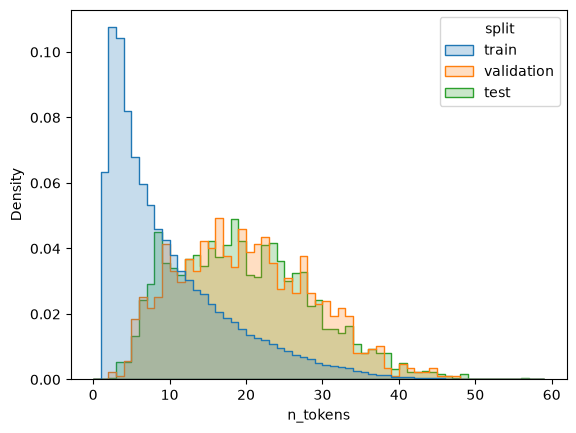

In [6]:
print(df.groupby("split").n_tokens.describe().round(1))
sns.histplot(data=df, x="n_tokens", hue="split", bins=range(0, 60), stat="density", common_norm=False, element="step")
plt.show()

## Vocabulary

5.70% van de woorden in de val set zijn out of vocab, dus hier rekening mee houden

In [7]:
train_vocab = Counter(t for toks in train.tokens for t in toks)
val_vocab = Counter(t for toks in val.tokens for t in toks)

print("train tokens:", sum(train_vocab.values()), "| types:", len(train_vocab))
print("types seen once:", sum(v == 1 for v in train_vocab.values()))

oov = sum(v for t, v in val_vocab.items() if t not in train_vocab)
print(f"validation OOV tokens: {oov / sum(val_vocab.values()):.2%}")

print(train_vocab.most_common(15))

train tokens: 634100 | types: 14801
types seen once: 504
validation OOV tokens: 5.70%
[('the', 27205), (',', 25980), ('a', 21609), ('and', 19920), ('of', 17907), ('.', 12830), ('to', 12538), ("'s", 8764), ('is', 8685), ('that', 7759), ('in', 7495), ('it', 7078), ('as', 5088), ('with', 4745), ('an', 4133)]


## Duplicates and overlap

In [8]:
print("duplicate train sentences:", train.sentence.duplicated().sum())
print("train sentences with conflicting labels:", (train.groupby("sentence").label.nunique() > 1).sum())
print("validation sentences also in train:", val.sentence.isin(set(train.sentence)).sum())

duplicate train sentences: 371
train sentences with conflicting labels: 5


validation sentences also in train: 0


## Tokenizer comparison: NLTK word level vs BPE


In [9]:
from from_tutorial.experiment import train_tokenizer

train_texts = train.sentence.str.strip().tolist()
val_texts = val.sentence.str.strip().tolist()

rows = []

# Word-level: NLTK word_tokenize
word_vocab = train_vocab
val_words = [w for toks in val.tokens for w in toks]
n_unk = sum(w not in word_vocab for w in val_words)
rows.append({
    "tokenizer": "word (NLTK)",
    "vocab size": len(word_vocab),
    "tokens per example": len(val_words) / len(val_texts),
    "unknown token rate": n_unk / len(val_words),
})

# BPE with a few vocabulary sizes
bpe = {}
for vocab_size in [500, 2000, 8000, 20000]:
    tok = train_tokenizer(train_texts, vocab_size=vocab_size, min_frequency=2)
    bpe[vocab_size] = tok
    enc = tok.encode_batch(val_texts)
    n_tokens = sum(len(e.ids) for e in enc)
    n_unk = sum(e.tokens.count("[UNK]") for e in enc)
    rows.append({
        "tokenizer": f"BPE ({vocab_size})",
        "vocab size": tok.get_vocab_size(),
        "tokens per example": n_tokens / len(val_texts),
        "unknown token rate": n_unk / n_tokens,
    })

pd.DataFrame(rows).round(4)

,tokenizer,vocab size,tokens per example,unknown token rate
0,word (NLTK),14801,19.5596,0.0570
1,BPE (500),500,42.0642,0.0001
2,BPE (2000),2000,30.2615,0.0001
3,BPE (8000),8000,23.7248,0.0001
4,BPE (20000),20000,21.6319,0.0002


In [10]:
# Same validation sentences, tokenised by NLTK and BPE
oov_sentence = next(s for s, toks in zip(val_texts, val.tokens) if any(w not in word_vocab for w in toks))
neg_sentence = next(s for s in val_texts if "n't" in s)

for s in [val_texts[0], neg_sentence, oov_sentence]:
    print("sentence:", s)
    print("  word (NLTK):", tokenize(s))
    print("  BPE 500:", bpe[500].encode(s).tokens)
    print("  BPE 8000:", bpe[8000].encode(s).tokens)
    print()

sentence: it 's a charming and often affecting journey .
  word (NLTK): ['it', "'s", 'a', 'charming', 'and', 'often', 'affecting', 'journey', '.']
  BPE 500: ['▁it', "▁'s", '▁a', '▁char', 'm', 'ing', '▁and', '▁of', 't', 'en', '▁a', 'ff', 'ect', 'ing', '▁j', 'our', 'n', 'e', 'y', '▁.']
  BPE 8000: ['▁it', "▁'s", '▁a', '▁charming', '▁and', '▁often', '▁affecting', '▁journey', '▁.']

sentence: you do n't have to know about music to appreciate the film 's easygoing blend of comedy and romance .
  word (NLTK): ['you', 'do', "n't", 'have', 'to', 'know', 'about', 'music', 'to', 'appreciate', 'the', 'film', "'s", 'easygoing', 'blend', 'of', 'comedy', 'and', 'romance', '.']
  BPE 500: ['▁you', '▁do', "▁n't", '▁have', '▁to', '▁k', 'n', 'ow', '▁about', '▁m', 'us', 'ic', '▁to', '▁a', 'pp', 're', 'c', 'i', 'ate', '▁the', '▁film', "▁'s", '▁e', 'as', 'y', 'g', 'o', 'ing', '▁bl', 'end', '▁of', '▁comedy', '▁and', '▁r', 'om', 'ance', '▁.']
  BPE 8000: ['▁you', '▁do', "▁n't", '▁have', '▁to', '▁know', '▁ab

## Save tokenized data


In [11]:
from pathlib import Path
from tokenizers import Tokenizer
from tokenizers.models import WordLevel
from tokenizers.pre_tokenizers import WhitespaceSplit

out = Path("data/tokenized")

# NLTK as a Hugging Face word-level Tokenizer (vocabulary = train tokens)
nltk_vocab = {"[UNK]": 0}
for t in sorted(Counter(t for toks in train.tokens for t in toks)):
    nltk_vocab[t] = len(nltk_vocab)
nltk_tok = Tokenizer(WordLevel(nltk_vocab, unk_token="[UNK]"))
nltk_tok.pre_tokenizer = WhitespaceSplit()

all_tokenizers = {"nltk": nltk_tok, **{f"bpe_{n}": t for n, t in bpe.items()}}

for name, tok in all_tokenizers.items():
    folder = out / name
    folder.mkdir(parents=True, exist_ok=True)
    tok.save(str(folder / "tokenizer.json"))
    for split_name, d in [("train", train), ("validation", val), ("test", test)]:
        texts = d.tokens.map(" ".join) if name == "nltk" else d.sentence.str.strip()
        enc = tok.encode_batch(texts.tolist())
        pd.DataFrame({
            "text": texts.values,
            "label": d.label.values,
            "tokens": [e.tokens for e in enc],
            "ids": [e.ids for e in enc],
        }).to_parquet(folder / f"{split_name}.parquet", index=False)

sorted(p.relative_to(out).as_posix() for p in out.rglob("*") if p.is_file())

['bpe_2000/test.parquet',
 'bpe_2000/tokenizer.json',
 'bpe_2000/train.parquet',
 'bpe_2000/validation.parquet',
 'bpe_20000/test.parquet',
 'bpe_20000/tokenizer.json',
 'bpe_20000/train.parquet',
 'bpe_20000/validation.parquet',
 'bpe_500/test.parquet',
 'bpe_500/tokenizer.json',
 'bpe_500/train.parquet',
 'bpe_500/validation.parquet',
 'bpe_8000/test.parquet',
 'bpe_8000/tokenizer.json',
 'bpe_8000/train.parquet',
 'bpe_8000/validation.parquet',
 'nltk/test.parquet',
 'nltk/tokenizer.json',
 'nltk/train.parquet',
 'nltk/validation.parquet']

## Data leakage and tree structure
The Stanford Sentiment Treebank gives a sentiment label to every node of each sentence's parse tree, not only to whole sentences. SST-2 train keeps all those nodes as separate rows (neutral ones removed), so a sentence and its sub-phrases are all in train. Validation and test only contain whole sentences.

Consequence: with random cross-validation folds, a held-out phrase usually has a parent sentence in the training folds, so the model has already seen its words with a (usually identical) label.

We approximate the tree with plain text: a row is a *sub-phrase* of another row if its words appear as a contiguous sequence inside it. A row that is not inside any longer row is treated as an original sentence (a root).

In [27]:
import numpy as np
from cv_helpers import make_folds   # the folds used in the model notebooks

train_text = train.sentence.str.strip().tolist()
train_label = train.label.tolist()
words = [s.split() for s in train_text]

def sub_spans(w):
    # all proper contiguous word sequences of a row (shorter than the row itself)
    n = len(w)
    for i in range(n):
        for j in range(i + 1, n + 1):
            if j - i < n:
                yield " ".join(w[i:j])

proper_spans = set()
for w in words:
    proper_spans.update(sub_spans(w))

roots = [i for i, t in enumerate(train_text) if t not in proper_spans]
print(f"train rows: {len(train_text)}")
print(f"rows that are not inside any longer row (~ original sentences): {len(roots)}")
print(f"=> on average {len(train_text) / len(roots):.1f} rows per original sentence")

train rows: 67349
rows that are not inside any longer row (~ original sentences): 6885
=> on average 9.8 rows per original sentence


### Text length of the parent sentences
Same plot as in the text length section, but with the train rows restricted to the parent sentences found above. If the parents look like validation and test, the length difference between the splits comes from the short sub-phrases.

                        count  mean  std  min   25%   50%   75%   max
split                                                                
test                   1821.0  19.2  8.9  2.0  12.0  18.0  25.0  56.0
train (all rows)      67349.0   9.4  8.1  1.0   3.0   7.0  13.0  53.0
train (parents only)   6885.0  19.4  9.3  2.0  12.0  19.0  26.0  53.0
validation              872.0  19.6  8.8  2.0  13.0  19.0  26.0  47.0


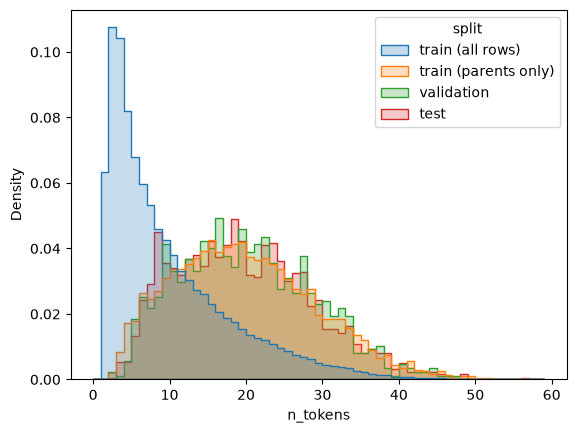

In [4]:
plot_df = pd.concat([
    train.assign(split="train (all rows)"),
    train.iloc[roots].assign(split="train (parents only)"),
    val.assign(split="validation"),
    test.assign(split="test"),
])
print(plot_df.groupby("split").n_tokens.describe().round(1))
sns.histplot(data=plot_df, x="n_tokens", hue="split", bins=range(0, 60), stat="density", common_norm=False, element="step")
plt.show()

### One sentence and its sub-phrases
All train rows whose words occur inside one example sentence, ordered by position.

In [28]:
label_of = {}
for t, l in zip(train_text, train_label):
    label_of.setdefault(t, l)

example = next(i for i in roots if 8 <= len(words[i]) <= 10)
w = words[example]
print("sentence:", train_text[example], "| label:", train_label[example], "\n")

rows = []
for i in range(len(w)):
    for j in range(i + 1, len(w) + 1):
        t = " ".join(w[i:j])
        if t in label_of:
            rows.append({"start": i, "end": j, "n_words": j - i, "phrase": t, "label": label_of[t]})
pd.DataFrame(rows).sort_values(["start", "end"], ascending=[True, False]).reset_index(drop=True)

sentence: disney again ransacks its archives for a quick-buck sequel . | label: 0 



,start,end,n_words,phrase,label
0,0,10,10,disney again ransacks its archives for a quick-buck sequel .,0
1,0,1,1,disney,1
2,1,10,9,again ransacks its archives for a quick-buck sequel .,0
3,2,10,8,ransacks its archives for a quick-buck sequel .,0
4,2,9,7,ransacks its archives for a quick-buck sequel,0
5,2,5,3,ransacks its archives,0
6,2,3,1,ransacks,0
7,5,9,4,for a quick-buck sequel,0
8,6,9,3,a quick-buck sequel,0
9,7,9,2,quick-buck sequel,0


### How many rows per sentence, and do they share the sentence's label?
If most sub-phrases have the same label as their sentence, a model that has seen the sentence can predict its phrases almost for free.

In [29]:
n_sub, same, total = [], 0, 0
for i in roots:
    labels = [label_of[t] for t in sub_spans(words[i]) if t in label_of]
    n_sub.append(len(labels))
    same += sum(l == train_label[i] for l in labels)
    total += len(labels)

print(f"sub-phrase rows per original sentence: mean {np.mean(n_sub):.1f}, median {np.median(n_sub):.0f}, max {max(n_sub)}")
print(f"sub-phrase rows with the same label as their sentence: {same / total:.1%}")

sub-phrase rows per original sentence: mean 12.4, median 12, max 47
sub-phrase rows with the same label as their sentence: 77.3%
